# Trait update: from 40 (v1) to 18 (v2) traits

This notebook documents the review that reduced the 40 personality traits of `DEFAULT_PRINCIPLES["v1"]` to the 18 traits kept in `"v2"` (see `src/feedback_forensics/annotation/principles.py`). The other 22 traits were removed to make space for newer traits.

Each trait was checked against four criteria:

1. **Rarely relevant** on the dataset (mostly insignificant strength values).
2. **(Almost) duplicate** of another trait.
3. **Low human inter-annotator agreement.**
4. **Feels odd** relative to the other traits.

All numbers are loaded from `16_trait_update.json` (next to this notebook), which holds the full analysis: per trait the metrics, the recommendation shown during the review with its reason, and the final decision. The notebook only displays that file; it does not recompute anything.

In [1]:
import json
import pathlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

pd.set_option("display.max_rows", None, "display.max_columns", None, "display.max_colwidth", None)

review = json.loads(pathlib.Path("16_trait_update.json").read_text())
traits = review["traits"]
by_name = {t["name"]: t for t in traits}
print(review["title"])
print(f"Decided: {review['decided_at']}  |  kept: {review['result']['n_kept']}  |  deleted: {review['result']['n_deleted']}")

Trait filter review: 40 v1 traits -> 18 v2 traits
Decided: 2026-11-24T19:07:52.877Z  |  kept: 18  |  deleted: 22


## 1. Data used

In [2]:
ma, hs = review["data"]["model_annotations"], review["data"]["human_study"]
display(Markdown(f'''
**Model annotations.** [`{ma["dataset"]}`, `{ma["version"]}`, commit `{ma["commit"][:8]}`]({ma["url"]}) ({ma["commit_title"]}, {ma["commit_date"][:10]})

- {ma["n_comparisons"]:,} comparisons of {ma["n_models"]} models against `{ma["reference_model"]}` on {ma["n_prompts"]} prompts ([prompts]({ma["prompts"]})).
- Annotator: `{ma["annotator"]["annotator_model"]}`, position debiasing: {ma["annotator"]["position_debias"]} (each comparison is annotated in both response orders, a vote is kept only if both agree).
- Traits annotated: {ma["traits_annotated"]}.
- {ma["files_note"]}

**Human study.** [`{hs["dataset"]}`, `{hs["file"]}`, commit `{hs["commit"][:8]}`]({hs["url"]}) ({hs["commit_date"][:10]})

- {hs["description"]}.
- Human agreement is computed between {" and ".join(f"`{a}`" for a in hs["human_annotators"])}.
- The AI annotator `{hs["ai_annotator_compared"]}` is compared against `{hs["human_reference_for_annotator_comparison"]}`.

**Note.** {review["data"]["earlier_round"]}
'''))
display(pd.DataFrame({"model": ma["models"]}).T)


**Model annotations.** [`rdnfn/ff-model-personality`, `data/v3`, commit `3dadb5ef`](https://huggingface.co/datasets/rdnfn/ff-model-personality/tree/3dadb5eff28e60911d95a3c8ebffbfc59018723f/data/v3) (Add updated v3, 2026-11-24)

- 15,644 comparisons of 36 models against `openai/gpt-4o-2024-11-20` on 445 prompts ([prompts](https://huggingface.co/datasets/rdnfn/ff-model-personality/blob/3dadb5eff28e60911d95a3c8ebffbfc59018723f/data/v3/config/prompts.json)).
- Annotator: `openrouter/google/gemini-3.5-flash-lite`, position debiasing: True (each comparison is annotated in both response orders, a vote is kept only if both agree).
- Traits annotated: DEFAULT_PRINCIPLES['v1'] (40 traits) in src/feedback_forensics/annotation/principles.py.
- The review used the 36 per-model annotation files, merged into one local combined_ap.json. The local per-model files are byte-identical (sha256) to those at this commit. The combined_ap.json at this commit is NOT the file used (it was removed in the next commit); later commits add further models that are not part of this review.

**Human study.** [`rdnfn/ff-public-results`, `data/main/arena_2024_human_annotations_ap.json`, commit `17465f41`](https://huggingface.co/datasets/rdnfn/ff-public-results/blob/17465f41cadd6f136a7f9d46448311ff45d1f796/data/main/arena_2024_human_annotations_ap.json) (2026-11-09)

- 101 LMArena (2024) comparisons of the Feedback Forensics paper's human study (Appendix G.2), 10 traits, 2 human annotators.
- Human agreement is computed between `Human (jovial-goldstine)` and `Human (stoic-goodall)`.
- The AI annotator `gemini-3.5-flash-lite (position-debiased)` is compared against `Human (aggregated, soft unanimous)`.

**Note.** A first pass used data/v2 (27 models, Gemini-2.5-Flash, single vote); its results were replaced by this v3 analysis and are not in this file.


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35
model,allenai/olmo-3-32b-think,allenai/olmo-3-7b-instruct,allenai/olmo-3-7b-think,anthropic/claude-3.7-sonnet,anthropic/claude-fable-5,anthropic/claude-fable-5.2,anthropic/claude-haiku-4.5,anthropic/claude-opus-4.7,anthropic/claude-opus-4.8,anthropic/claude-opus-5,anthropic/claude-opus-5.5,anthropic/claude-sonnet-4,anthropic/claude-sonnet-4.5,google/gemini-2.5-pro,google/gemini-3-pro-preview,google/gemini-3.1-pro-preview,meta-llama/llama-4-maverick,mistralai/magistral-medium-2506,mistralai/mistral-large-2512,mistralai/mistral-large-4-0,mistralai/mistral-medium-3-5,mistralai/mistral-medium-3.1,moonshotai/kimi-k2,openai/gpt-3.5-turbo,openai/gpt-4.1-mini,openai/gpt-5,openai/gpt-5-chat,openai/gpt-5.1,openai/gpt-5.1-chat,openai/gpt-5.3-chat,openai/gpt-5.6-sol,openai/gpt-6-sol,openai/gpt-6.1-sol,openai/gpt-oss-20b,x-ai/grok-4,z-ai/glm-4.6


## 2. Metrics

In [3]:
display(pd.DataFrame(review["definitions"].items(), columns=["metric", "definition"]).set_index("metric"))

,definition
metric,
relevance_share,share of comparisons where the annotator picked one response in both response orders
both_rate,share of comparisons where the annotator said both responses show the trait equally
order_disagreement_rate,share of all comparisons where the two response orders gave different votes (no vote kept)
order_dependent_share,order disagreements / (order disagreements + relevant comparisons); flag order_dependent at >= 0.6
strength,"per model vs the reference: (n target model picked - n reference picked) / n comparisons, i.e. relevance x Cohen's kappa with chance agreement 0.5"
significant,"one-tailed binomial test of agreement vs disagreement as in the app, p < 0.05 / 1440 (Bonferroni over traits x models); flag rarely_relevant at <= 5 of 36 models"
closest_traits,4 traits with highest absolute vote correlation (votes coded +1 / 0 / -1 over all comparisons)
same_pick_when_both_relevant,share of comparisons where both are relevant and pick the same response
model_profile_correlation,Pearson correlation of the per-model strengths of two traits


## 3. Kept vs deleted traits

Medians over the traits in each group, and how many traits in each group carry each flag.

In [4]:
def summary_column(s):
    return {
        "number of traits": s["n"],
        "median relevance": f'{s["median_relevance"]:.1%}',
        f'median models significant (of {ma["n_models"]})': s["median_models_significant"],
        "median max |strength|": f'{s["median_max_abs_strength"]:.2f}',
        "median order-dependent share": f'{s["median_order_dependent_share"]:.0%}',
        "traits in human study": s["n_in_human_study"],
        "median human kappa (combined)": f'{s["median_human_kappa_combined"]:.2f}',
        **{f"flag: {k.replace('_', ' ')}": v for k, v in s["flag_counts"].items()},
        "decision differs from recommendation": s["n_where_user_differed_from_recommendation"],
    }

display(pd.DataFrame({k: summary_column(v) for k, v in review["summary"].items()}))

,kept,deleted
number of traits,18,22
median relevance,22.9%,3.1%
median models significant (of 36),22.5,5.5
median max |strength|,0.48,0.08
median order-dependent share,37%,64%
traits in human study,3,7
median human kappa (combined),0.43,0.43
flag: rarely relevant,0,11
flag: duplicate group,8,12
flag: low human agreement,0,3


In [5]:
def trait_table(ts, with_reason=False):
    rows = []
    for t in ts:
        h, s, rec = t["human_study"], t["strength"], t["recommendation"]
        row = {
            "trait": t["name"],
            "relevance": f'{t["relevance"]["share"]:.1%}',
            "models signif.": f'{s["n_models_significant"]} (+{s["n_significant_above_reference"]}/-{s["n_significant_below_reference"]})',
            "max |strength|": f'{s["max_abs"]:.2f}',
            "order-dependent": f'{t["order_dependent_share"]:.0%}',
            "human kappa": f'{h["human_vs_human"]["kappa_combined"]:.2f}' if h else "",
            "annotator-human kappa": f'{h["annotator_vs_humans"]["kappa_combined"]:.2f}' if h else "",
            "closest trait (same pick)": f'{t["closest_traits"][0]["name"]} ({t["closest_traits"][0]["same_pick_when_both_relevant"]:.0%})',
            "flags": ", ".join(f.replace("_", " ") for f in t["flags"]),
            "recommended": rec["verdict"] + (" (close call)" if rec["close_call"] else ""),
        }
        if with_reason:
            row["reason given in review"] = rec["reason"]
        rows.append(row)
    return pd.DataFrame(rows).set_index("trait")

kept = [t for t in traits if t["final_decision"] == "keep"]
deleted = [t for t in traits if t["final_decision"] == "delete"]

### Kept traits (v2)

`models signif.` gives the number of models whose strength differs significantly from the reference, and in brackets how many are above (+) and below (-) the reference. Human kappa values are empty for traits that were not part of the human study.

In [6]:
display(trait_table(kept))

,relevance,models signif.,max |strength|,order-dependent,human kappa,annotator-human kappa,closest trait (same pick),flags,recommended
trait,,,,,,,,,
uses more bold and italics text,63.8%,33 (+26/-7),0.77,28%,,,has more structured formatting (95%),duplicate group,delete (close call)
has more structured formatting,54.9%,31 (+24/-7),0.78,33%,0.55,0.50,is more concise (5%),duplicate group,keep
more actively engages with the user,48.8%,29 (+25/-4),0.64,30%,,,ends with a follow-up question (98%),duplicate group,delete (close call)
is more verbose,70.1%,27 (+16/-11),0.88,30%,0.43,0.53,is more concise (0%),duplicate group,delete (close call)
provides a numbered list format,33.2%,27 (+8/-19),0.55,32%,,,has more structured formatting (87%),duplicate group,delete (close call)
ends with a follow-up question,27.8%,24 (+18/-6),0.55,22%,0.26,0.63,more actively engages with the user (98%),duplicate group,keep
provides more examples,32.9%,24 (+20/-4),0.48,37%,,,is more concise (6%),,keep
uses more formal language,43.5%,23 (+2/-21),0.65,49%,,,is more verbose (83%),,keep
includes more references to other sources,10.4%,23 (+22/-1),0.36,38%,,,is more concise (9%),,keep


### Deleted traits

In [7]:
display(trait_table(deleted))

,relevance,models signif.,max |strength|,order-dependent,human kappa,annotator-human kappa,closest trait (same pick),flags,recommended
trait,,,,,,,,,
is more creative and original,32.6%,33 (+32/-1),0.69,35%,,,expresses more emotion (89%),,keep
is more factually correct,32.2%,29 (+25/-4),0.58,51%,0.59,0.22,makes more confident statements (94%),odd one out,delete (close call)
is more concise,77.8%,28 (+10/-18),0.90,21%,0.43,0.51,is more verbose (0%),duplicate group,keep (close call)
is more polite,15.7%,27 (+4/-23),0.40,67%,0.12,0.43,has a friendlier tone (93%),"duplicate group, low human agreement, order dependent",delete
makes more confident statements,25.7%,27 (+25/-2),0.40,69%,0.10,0.34,is more factually correct (94%),"low human agreement, order dependent",delete (close call)
uses more casual language,11.5%,26 (+26/-0),0.53,61%,,,uses more formal language (1%),order dependent,keep (close call)
expresses more emotion,16.3%,21 (+16/-5),0.39,47%,,,uses a more enthusiastic tone (96%),duplicate group,delete (close call)
"uses more personal pronouns (I, we, you)",47.0%,21 (+15/-6),0.57,42%,,,more actively engages with the user (91%),odd one out,delete (close call)
more strictly follows the requested output format,5.6%,9 (+8/-1),0.08,73%,0.12,0.22,is more factually correct (97%),"low human agreement, order dependent, odd one out",delete


## 4. Reasons

The recommendation and reason shown for each trait during the review, with the final decision. The decision was made by the user and differs from the recommendation for the traits listed first.

In [8]:
differ = [t for t in traits if not t["recommendation"]["user_followed"]]
display(pd.DataFrame([{"trait": t["name"], "recommended": t["recommendation"]["verdict"], "final decision": t["final_decision"],
                       "reason given for the recommendation": t["recommendation"]["reason"]} for t in differ]).set_index("trait"))

,recommended,final decision,reason given for the recommendation
trait,,,
uses more bold and italics text,delete,keep,"Strongest signal in the data (33 of 36 models), but near-duplicate of structured formatting (same pick 95%, profile correlation 0.93). Keep this one instead if you prefer the more concrete wording; structured formatting has the human validation."
more actively engages with the user,delete,keep,"Strong signal (29 models) but vague: it contains the follow-up question (94% of those cases, same pick 98%) and otherwise tracks friendlier tone (profile correlation 0.87) and personal pronouns (0.87)."
is more verbose,delete,keep,Exact opposite of “is more concise”. Close to a coin flip: concise is relevant slightly more often (78% vs 70%) and its votes depend less on response order (21% vs 29%). Human agreement is the same for both (κ 0.43). Keep verbose instead if you prefer the wording.
provides a numbered list format,delete,keep,"Sub-case of structured formatting (70% of its cases, same pick 87%). In 28.5% of comparisons both responses use numbered lists, so the annotator abstains almost as often as it picks. Strong signal on its own though (27 models)."
uses more mathematical symbols and notation,delete,keep,"Depends on the topic of the prompt more than on the model. Relevant in 15%, significant for 10 models. Feels out of place next to tone and style traits."
is more creative and original,keep,delete,"Relevant in 33%, 33 models significant, up to 0.69. Somewhat evaluative, but no duplicate."
is more concise,keep,delete,"The one to keep from the length pair: relevant in 78% of comparisons, 28 models significant, and the least order-dependent of the frequent traits (21%). Close call against verbose."
uses more casual language,keep,delete,"26 models significant, all above GPT-4o, up to 0.53. The vote flips with response order in 61% of the cases where it votes, which costs relevance (11.5%) but the surviving votes are consistent. Opposite pick to formal language in 99% of shared cases, but they share only 19% of their cases."


In [9]:
lines = []
for label, ts in [("Kept", kept), ("Deleted", deleted)]:
    lines.append(f"### {label}\n")
    for t in ts:
        rec = t["recommendation"]
        note = "" if rec["user_followed"] else f" *(recommended: {rec['verdict']})*"
        lines.append(f"- **{t['name']}**{note}: {rec['reason']}")
    lines.append("")
display(Markdown("\n".join(lines)))

### Kept

- **uses more bold and italics text** *(recommended: delete)*: Strongest signal in the data (33 of 36 models), but near-duplicate of structured formatting (same pick 95%, profile correlation 0.93). Keep this one instead if you prefer the more concrete wording; structured formatting has the human validation.
- **has more structured formatting**: Relevant in 55%, 31 models significant, good human agreement (κ 0.55).
- **more actively engages with the user** *(recommended: delete)*: Strong signal (29 models) but vague: it contains the follow-up question (94% of those cases, same pick 98%) and otherwise tracks friendlier tone (profile correlation 0.87) and personal pronouns (0.87).
- **is more verbose** *(recommended: delete)*: Exact opposite of “is more concise”. Close to a coin flip: concise is relevant slightly more often (78% vs 70%) and its votes depend less on response order (21% vs 29%). Human agreement is the same for both (κ 0.43). Keep verbose instead if you prefer the wording.
- **provides a numbered list format** *(recommended: delete)*: Sub-case of structured formatting (70% of its cases, same pick 87%). In 28.5% of comparisons both responses use numbered lists, so the annotator abstains almost as often as it picks. Strong signal on its own though (27 models).
- **ends with a follow-up question**: Relevant in 28%, 24 models significant. Concrete and checkable, and the second least order-dependent trait (22%). Human κ is low (0.26) because one annotator rarely marked it.
- **provides more examples**: Relevant in 33%, 24 models significant. Correlates with length but measures something a reader would name separately.
- **uses more formal language**: Relevant in 44%, 23 models significant, 21 of them below GPT-4o. Order-dependent in about half of its cases.
- **includes more references to other sources**: Relevant in 10.5%, 23 models significant. No close duplicate.
- **has a friendlier tone**: Relevant in 32%, 22 models significant, up to 0.63. The trait to keep from the warmth group.
- **uses a more enthusiastic tone**: Relevant in 18%, 20 models significant. The one to keep from the positive-affect group; “expresses more emotion” would do equally well.
- **uses more emojis**: Relevant in 8.5%, 16 models significant. The least order-dependent trait of all (19%): a surface feature, but one the annotator applies reliably and readers notice.
- **compliments the user's question or prompt**: Relevant in 10%, 16 models significant, up to 0.48. The clearest sycophancy signal in the set.
- **uses more humour**: Only 4% relevance, but 14 models significant, all above GPT-4o. No close duplicate.
- **actively engages the reader with rhetorical questions**: Relevant in 7%, 14 models significant, all above GPT-4o. No close duplicate.
- **uses more mathematical symbols and notation** *(recommended: delete)*: Depends on the topic of the prompt more than on the model. Relevant in 15%, significant for 10 models. Feels out of place next to tone and style traits.
- **acknowledges own limitations or uncertainty more**: Relevant in 13%, significant for 8 models, max strength 0.17. No duplicate, and the only uncertainty trait left if confident statements goes.
- **includes more ethical considerations**: Weaker with the v3 annotator: relevant in 5.4%, significant for 6 models, max strength 0.09. Just above the rarely-relevant line. Kept because nothing else covers it.

### Deleted

- **is more creative and original** *(recommended: keep)*: Relevant in 33%, 33 models significant, up to 0.69. Somewhat evaluative, but no duplicate.
- **is more factually correct**: A quality judgement, not a personality trait, and the annotator cannot verify facts. Very strong signal in v3 (29 models, up to 0.58), which mostly ranks newer models above GPT-4o. In half of the cases where it votes, the vote flips with response order. Humans agree with each other on it reasonably (κ 0.59), but the annotator matches them worst of the ten validated traits (κ 0.22): it finds the trait relevant on 31 of 101 comparisons against 19 for the humans, and picks the same response in 8 of the 10 shared cases.
- **is more concise** *(recommended: keep)*: The one to keep from the length pair: relevant in 78% of comparisons, 28 models significant, and the least order-dependent of the frequent traits (21%). Close call against verbose.
- **is more polite**: 87% of its cases are friendlier-tone cases with the same pick in 93%. The two human annotators barely agreed on it (κ 0.12), and the annotator's vote flips with response order in two thirds of the cases where it votes at all.
- **makes more confident statements**: Fails both reliability checks: human κ 0.10, and the annotator's vote flips with response order in 57% of all comparisons (69% of those where it votes). The surviving votes still give a strong signal (27 models), so reword and re-validate it if you want confidence covered.
- **uses more casual language** *(recommended: keep)*: 26 models significant, all above GPT-4o, up to 0.53. The vote flips with response order in 61% of the cases where it votes, which costs relevance (11.5%) but the surviving votes are consistent. Opposite pick to formal language in 99% of shared cases, but they share only 19% of their cases.
- **expresses more emotion**: Near-duplicate of enthusiastic tone (same pick 96%, profile correlation 0.93) at about the same relevance and signal. Keep either one; enthusiastic is the more specific wording.
- **uses more personal pronouns (I, we, you)**: A word-count proxy, not a trait a reader would name. Its model ranking follows friendlier tone (0.89) and “actively engages” (0.87). Strong signal though (21 models), so a close call.
- **more strictly follows the requested output format**: Relevant in 5.6% of comparisons. Low human agreement (κ 0.12) and the most order-dependent of the non-rare traits (73%). Only meaningful when the prompt requests a format.
- **is more optimistic**: Relevant in 4.1% of comparisons, 8 models significant, max strength 0.08. 77% of its cases are covered by enthusiastic tone with the same pick in 97%.
- **is more empathetic to the user**: Relevant in only 3.8% of comparisons with the v3 annotator (20.8% in v2), 7 models significant, max strength 0.10. 88% of its cases are friendlier-tone cases with the same pick in 96%.
- **provides conclusions without full reasoning**: Relevant in 2.4% of comparisons, 4 models significant. Reads as a quality defect, not a personality trait, and is the inverse of structure and length (opposite pick in 96–97% of shared cases).
- **has a more avoidant tone**: Relevant in 2.4% of comparisons, significant for 1 model. Same pick as “refuses to answer” in every shared case.
- **agrees more with the user**: Relevant in 2.3% of comparisons, significant for 1 model. In a further 25% the vote flips with response order. With it the whole agreement group goes; “compliments the user” remains as the sycophancy signal.
- **includes inappropriate language**: Never relevant: 6 of 15,644 comparisons. No model differs from GPT-4o.
- **suggests illegal activities**: Relevant in 0.4% of comparisons, not significant for any model. The prompt set does not elicit it.
- **is more offensive**: Never relevant: 2 of 15,644 comparisons. Duplicate of “inappropriate language”.
- **contains less harmful information**: Relevant in 0.3% of comparisons. The annotator's vote flips with response order in 28% of all comparisons, the clearest sign that it cannot apply this trait. Also the only trait phrased as “less of something”.
- **refuses to answer the question**: Relevant in 1.3% of comparisons and not significant for any model, so it fails your first criterion on this prompt set. Close call because it is a clear behaviour with the highest human agreement of all traits (κ 0.74); worth keeping if new prompts will elicit refusals.
- **agrees with user even if factually incorrect**: Relevant in 0.4% of comparisons, not significant for any model. Asks the annotator to judge facts as well as tone.
- **reinforces user's beliefs more**: Relevant in 1.8% of comparisons, not significant for any model. Picks the same response as “agrees more with the user” every time.
- **reinforces user's anger more**: Relevant in 0.1% of comparisons (21 cases), not significant for any model. Needs an angry user, which the prompts rarely have.


## 5. Duplicate groups

Groups of traits that largely select the same response. The criterion was not applied strictly: in the formatting and engagement groups all traits were kept.

In [10]:
display(pd.DataFrame([{"group": g["name"], "kept": ", ".join(g["kept"]) or "-", "deleted": ", ".join(g["deleted"]) or "-", "note": g["note"]}
                      for g in review["duplicate_groups"]]).set_index("group"))

,kept,deleted,note
group,,,
Length,is more verbose,is more concise,"Exact opposites: when both are relevant they pick opposite responses in 100% of cases, and the model profiles correlate at −0.99. One of them carries all the information. Which one is close to a coin flip."
Formatting,"has more structured formatting, uses more bold and italics text, provides a numbered list format",-,"Bold/italics picks the same response as structured formatting in 95% of shared cases (profile correlation 0.93). Numbered list is a narrower sub-case: 70% of its relevant cases are also structured-formatting cases, with the same pick in 87%."
Engagement,"ends with a follow-up question, more actively engages with the user",-,"94% of follow-up-question cases are also “actively engages” cases, with the same pick in 98%. The reverse is only 53%: “actively engages” also fires on friendliness and direct address."
Warmth,has a friendlier tone,"is more polite, is more empathetic to the user","87% of polite cases and 88% of empathetic cases are also friendlier-tone cases, with the same pick in 93% and 96%."
Positive affect,uses a more enthusiastic tone,"expresses more emotion, is more optimistic","Enthusiastic and “expresses more emotion” pick the same response in 96% of shared cases (profile correlation 0.93), with similar relevance. Optimistic is covered by either of them in 77% of its cases."
Agreement with the user,-,"agrees more with the user, reinforces user's beliefs more, agrees with user even if factually incorrect",All three pick the same response in 98–100% of shared cases. None is relevant in more than 2.5% of comparisons and none is significant for more than one model.
Refusal,-,"refuses to answer the question, has a more avoidant tone",Same response picked in 100% of shared cases. Both are rare on this prompt set: 1.3% and 2.4% of comparisons.
Unsafe language,-,"includes inappropriate language, is more offensive","Each is relevant in at most 6 of 15,644 comparisons, so the choice between them does not matter on this data."


### Closest traits of each kept trait

For each kept trait the four traits with the most similar votes among all 40. `same pick`: how often both traits select the same response where both are relevant. `overlap`: Jaccard overlap of the comparisons where they are relevant. `profile r`: correlation of the per-model strengths.

In [11]:
rows = []
for t in kept:
    for n in t["closest_traits"]:
        rows.append({"trait": t["name"], "closest trait": n["name"], "also kept": "yes" if by_name[n["name"]]["final_decision"] == "keep" else "",
                     "same pick": f'{n["same_pick_when_both_relevant"]:.0%}', "overlap": f'{n["relevance_overlap_jaccard"]:.2f}',
                     "profile r": f'{n["model_profile_correlation"]:+.2f}'})
display(pd.DataFrame(rows).set_index(["trait", "closest trait"]))

also kept  \
trait                                                 closest trait                                         
uses more bold and italics text                       has more structured formatting                  yes   
                                                      is more concise                                       
                                                      is more verbose                                 yes   
                                                      provides more examples                          yes   
has more structured formatting                        is more concise                                       
                                                      is more verbose                                 yes   
                                                      uses more bold and italics text                 yes   
                                                      provides a numbered list format                 yes   
more actively engages with the user                   ends with a follow-up question                  yes   
                                                      has a friendlier tone                           yes   
                                                      uses more personal pronouns (I, we, you)              
                                                      is more concise                                       
is more verbose                                       is more concise                                       
                                                      has more structured formatting                  yes   
                                                      uses more bold and italics text                 yes   
                                                      provides more examples                          yes   
provides a numbered list format                       has more structured formatting                  yes   
                                                      is more concise                                       
                                                      is more verbose                                 yes   
                                                      uses more bold and italics text                 yes   
ends with a follow-up question                        more actively engages with the user             yes   
                                                      has a friendlier tone                           yes   
                                                      uses more personal pronouns (I, we, you)              
                                                      is more polite                                        
provides more examples                                is more concise                                       
                                                      is more verbose                                 yes   
                                                      has more structured formatting                  yes   
                                                      uses more bold and italics text                 yes   
uses more formal language                             is more verbose                                 yes   
                                                      is more concise                                       
                                                      has more structured formatting                  yes   
                                                      uses more casual language                             
includes more references to other sources             is more concise                                       
                                                      provides more examples                          yes   
                                                      has more structured formatting                  yes   
                                                      is more v

## 6. Human study

Only 10 of the 40 traits have human labels. `kappa combined` is Cohen's kappa over three labels (response A, response B, not relevant), so it mixes two questions: whether the trait applies at all (`kappa relevance`) and which response shows it more (`same pick`, among the comparisons both found relevant, with their number in brackets). Most disagreement is about relevance. For rare traits the numbers rest on very few comparisons.

In [12]:
rows = []
for t in traits:
    h = t["human_study"]
    if not h:
        continue
    row = {"trait": t["name"], "final decision": t["final_decision"]}
    for label, key in [("human-human", "human_vs_human"), ("annotator-human", "annotator_vs_humans")]:
        a = h[key]
        row[(label, "kappa combined")] = f'{a["kappa_combined"]:.2f}'
        row[(label, "kappa relevance")] = f'{a["kappa_relevance"]:.2f}'
        row[(label, "same pick")] = f'{a["same_pick_when_both_relevant"]:.0%} ({a["n_both_relevant"]})'
    rows.append(row)
df = pd.DataFrame(rows).set_index(["trait", "final decision"])
df.columns = pd.MultiIndex.from_tuples(df.columns)
display(df.sort_values(("human-human", "kappa combined"), ascending=False))

human-human  \
                                                                 kappa combined   
trait                                             final decision                  
refuses to answer the question                    delete                   0.74   
is more factually correct                         delete                   0.59   
has more structured formatting                    keep                     0.55   
has a more avoidant tone                          delete                   0.55   
is more verbose                                   keep                     0.43   
is more concise                                   delete                   0.43   
ends with a follow-up question                    keep                     0.26   
is more polite                                    delete                   0.12   
more strictly follows the requested output format delete                   0.12   
makes more confident statements                   delete                   0.10   

                                                                                  \
                                                                 kappa relevance   
trait                                             final decision                   
refuses to answer the question                    delete                    0.74   
is more factually correct                         delete                    0.61   
has more structured formatting                    keep                      0.43   
has a more avoidant tone                          delete                    0.55   
is more verbose                                   keep                      0.21   
is more concise                                   delete                    0.23   
ends with a follow-up question                    keep                      0.25   
is more polite                                    delete                    0.09   
more strictly follows the requested output format delete                    0.16   
makes more confident statements                   delete                    0.10   

                                                                            \
                                                                 same pick   
trait                                             final decision             
refuses to answer the question                    delete          100% (3)   
is more factually correct                         delete          90% (10)   
has more structured formatting                    keep            92% (52)   
has a more avoidant tone                          delete          100% (5)   
is more verbose                                   keep            89% (57)   
is more concise                                   delete          89% (56)   
ends with a follow-up question                    keep            100% (2)   
is more polite                                    delete          100% (3)   
more strictly follows the requested output format delete           50% (2)   
makes more confident statements                   delete           67% (3)   

                                                                 annotator-human  \
                                                                  kappa combined   
trait                                             final decision                   
refuses to answer the question                    delete                    0.74   
is more factually correct                         delete                    0.22   
has more structured formatting                    keep                      0.50   
has a more avoidant tone                          delete                    0.40   
is more verbose                                   keep                      0.53   
is more concise                                   delete                    0.51   
ends with a follow-up question                    keep                      0.63   
is more polite                          

## 7. Order dependence

Share of comparisons with a vote in at least one response order where the two orders disagreed. It is available for all 40 traits and was used as a stand-in for annotator reliability where no human labels exist. Flagged at 60% or more (dashed line).

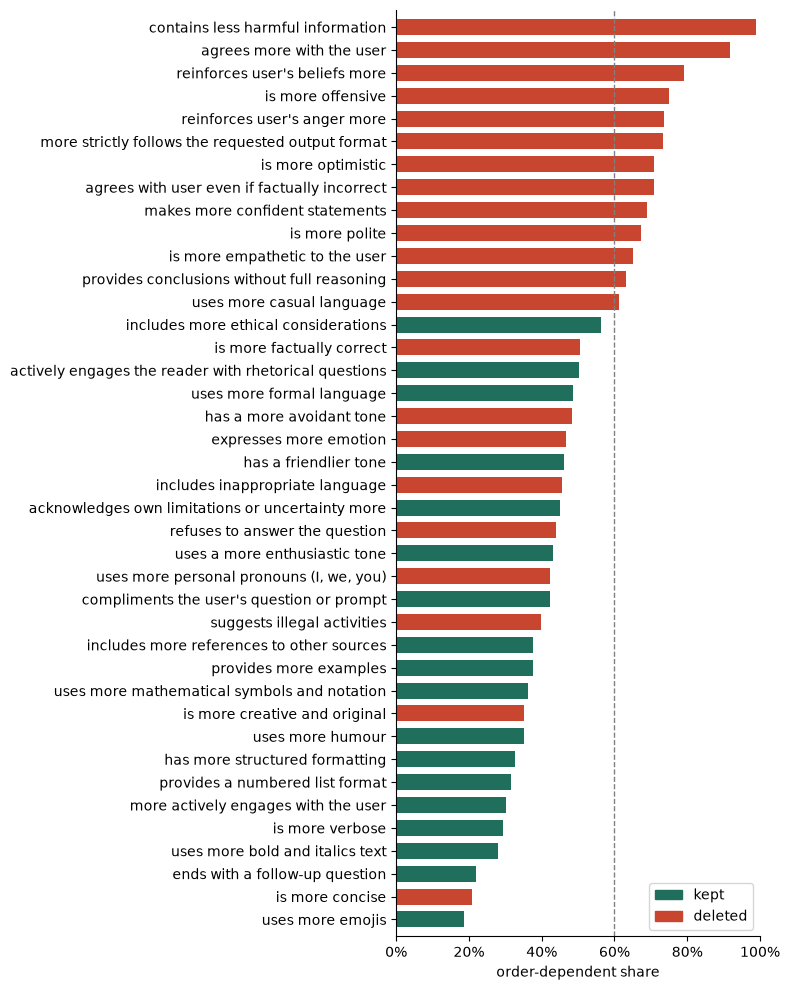

In [13]:
order = sorted(traits, key=lambda t: t["order_dependent_share"])
fig, ax = plt.subplots(figsize=(8, 10))
colors = ["#1f6f5c" if t["final_decision"] == "keep" else "#c8452f" for t in order]
ax.barh([t["name"] for t in order], [t["order_dependent_share"] for t in order], color=colors, height=0.7)
ax.axvline(0.6, color="grey", linestyle="--", linewidth=1)
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlabel("order-dependent share")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color="#1f6f5c"), plt.Rectangle((0, 0), 1, 1, color="#c8452f")], labels=["kept", "deleted"], loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
ax.margins(y=0.01)
plt.tight_layout()
plt.show()

## 8. Strength per model

Strength of each trait for each model relative to the reference model (blue: the model shows the trait more than the reference, red: less). Cells that are not significant after Bonferroni correction are left blank. Kept traits are shown above the line, deleted traits below.

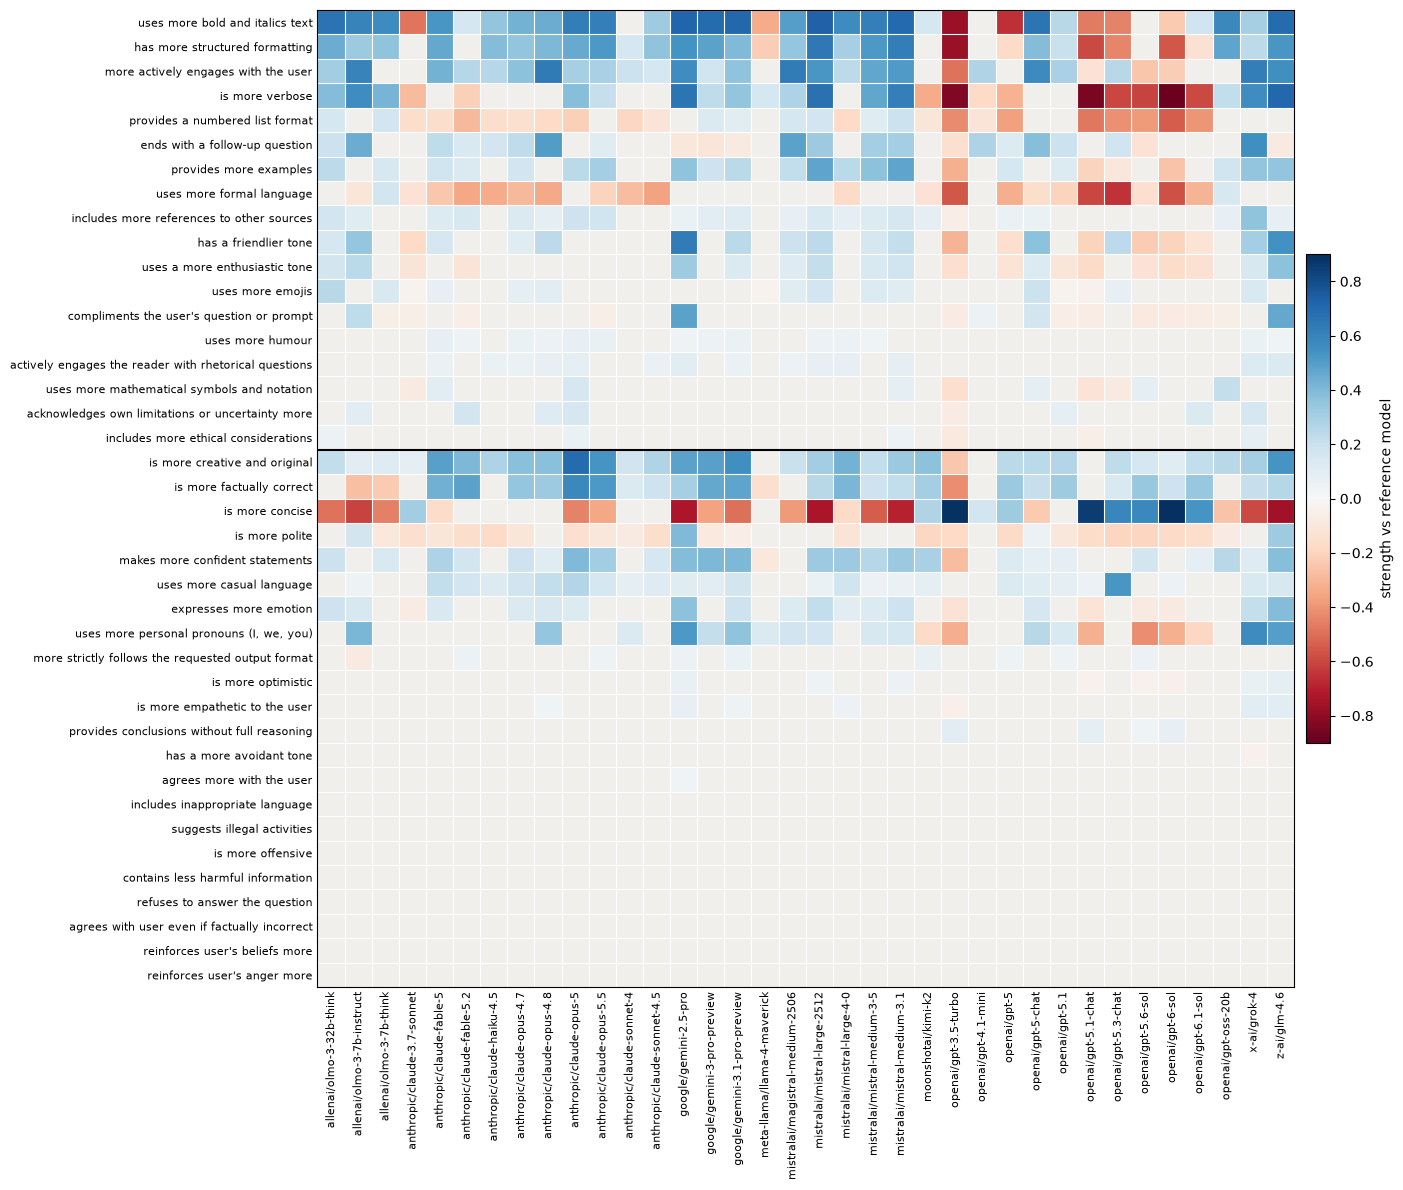

In [14]:
models = ma["models"]
ordered = kept + deleted
S = np.array([[t["strength"]["per_model"][m]["strength"] if t["strength"]["per_model"][m]["significant"] else np.nan for m in models] for t in ordered])
fig, ax = plt.subplots(figsize=(15, 12))
cmap = plt.get_cmap("RdBu").copy()
cmap.set_bad("#f0efec")
im = ax.imshow(S, cmap=cmap, vmin=-0.9, vmax=0.9, aspect="auto")
ax.set_xticks(range(len(models)), models, rotation=90, fontsize=8)
ax.set_yticks(range(len(ordered)), [t["name"] for t in ordered], fontsize=8)
ax.axhline(len(kept) - 0.5, color="black", linewidth=1.5)
ax.set_xticks(np.arange(-0.5, len(models)), minor=True)
ax.set_yticks(np.arange(-0.5, len(ordered)), minor=True)
ax.grid(which="minor", color="white", linewidth=0.8)
ax.tick_params(which="both", length=0)
fig.colorbar(im, ax=ax, shrink=0.5, pad=0.01, label="strength vs reference model")
plt.tight_layout()
plt.show()

### Strength values of the kept traits

In [15]:
display(pd.DataFrame({t["name"]: {m: t["strength"]["per_model"][m]["strength"] for m in models} for t in kept}).T.round(2))

,allenai/olmo-3-32b-think,allenai/olmo-3-7b-instruct,allenai/olmo-3-7b-think,anthropic/claude-3.7-sonnet,anthropic/claude-fable-5,anthropic/claude-fable-5.2,anthropic/claude-haiku-4.5,anthropic/claude-opus-4.7,anthropic/claude-opus-4.8,anthropic/claude-opus-5,anthropic/claude-opus-5.5,anthropic/claude-sonnet-4,anthropic/claude-sonnet-4.5,google/gemini-2.5-pro,google/gemini-3-pro-preview,google/gemini-3.1-pro-preview,meta-llama/llama-4-maverick,mistralai/magistral-medium-2506,mistralai/mistral-large-2512,mistralai/mistral-large-4-0,mistralai/mistral-medium-3-5,mistralai/mistral-medium-3.1,moonshotai/kimi-k2,openai/gpt-3.5-turbo,openai/gpt-4.1-mini,openai/gpt-5,openai/gpt-5-chat,openai/gpt-5.1,openai/gpt-5.1-chat,openai/gpt-5.3-chat,openai/gpt-5.6-sol,openai/gpt-6-sol,openai/gpt-6.1-sol,openai/gpt-oss-20b,x-ai/grok-4,z-ai/glm-4.6
uses more bold and italics text,0.67,0.60,0.56,-0.48,0.52,0.16,0.36,0.42,0.44,0.62,0.62,0.06,0.32,0.71,0.69,0.71,-0.33,0.50,0.73,0.57,0.62,0.70,0.16,-0.77,-0.03,-0.65,0.66,0.25,-0.47,-0.44,0.01,-0.24,0.18,0.58,0.30,0.69
has more structured formatting,0.44,0.33,0.36,-0.09,0.46,0.09,0.39,0.35,0.40,0.45,0.52,0.16,0.36,0.54,0.48,0.40,-0.22,0.35,0.64,0.30,0.52,0.62,0.11,-0.78,-0.01,-0.17,0.39,0.20,-0.59,-0.44,-0.09,-0.56,-0.13,0.47,0.24,0.53
more actively engages with the user,0.31,0.60,0.00,-0.08,0.42,0.25,0.26,0.37,0.64,0.30,0.29,0.19,0.16,0.56,0.18,0.36,-0.02,0.63,0.53,0.24,0.47,0.51,-0.02,-0.49,0.27,0.12,0.58,0.29,-0.13,0.25,-0.25,-0.22,-0.01,0.03,0.62,0.55
is more verbose,0.39,0.56,0.42,-0.28,0.03,-0.22,-0.15,-0.07,0.02,0.38,0.21,0.04,-0.13,0.66,0.23,0.36,0.16,0.28,0.67,0.10,0.47,0.61,-0.34,-0.83,-0.18,-0.31,0.10,-0.10,-0.85,-0.60,-0.61,-0.88,-0.60,0.22,0.56,0.71
provides a numbered list format,0.16,0.02,0.18,-0.16,-0.16,-0.29,-0.16,-0.15,-0.18,-0.21,-0.10,-0.18,-0.12,0.09,0.13,0.10,0.03,0.16,0.17,-0.18,0.11,0.19,-0.11,-0.42,-0.12,-0.37,-0.08,-0.08,-0.47,-0.41,-0.38,-0.55,-0.40,-0.06,-0.05,0.08
ends with a follow-up question,0.19,0.45,0.01,-0.03,0.23,0.14,0.17,0.23,0.50,0.07,0.11,0.04,0.06,-0.10,-0.11,-0.08,-0.06,0.48,0.33,0.05,0.31,0.31,-0.05,-0.14,0.28,0.12,0.39,0.20,0.06,0.18,-0.13,-0.07,0.02,-0.02,0.55,-0.08
provides more examples,0.24,0.07,0.15,-0.10,0.18,0.13,0.04,0.17,0.09,0.24,0.31,0.09,0.09,0.36,0.18,0.24,-0.03,0.22,0.48,0.24,0.37,0.47,0.01,-0.32,-0.09,0.16,0.07,0.13,-0.20,-0.10,-0.04,-0.25,-0.08,0.18,0.35,0.35
uses more formal language,0.09,-0.11,0.17,-0.13,-0.24,-0.35,-0.33,-0.29,-0.34,-0.13,-0.20,-0.28,-0.36,0.05,-0.09,-0.12,-0.09,-0.09,0.05,-0.17,0.00,0.03,-0.13,-0.56,-0.02,-0.33,-0.16,-0.20,-0.60,-0.65,-0.15,-0.58,-0.30,0.14,0.02,0.04
includes more references to other sources,0.17,0.11,0.05,-0.01,0.12,0.15,0.00,0.13,0.08,0.18,0.18,0.01,0.02,0.06,0.09,0.12,0.02,0.07,0.14,0.08,0.13,0.15,0.08,-0.06,0.01,0.06,0.06,0.04,-0.04,-0.01,0.03,-0.04,0.02,0.08,0.36,0.08
has a friendlier tone,0.16,0.35,-0.08,-0.18,0.15,-0.07,-0.03,0.11,0.24,0.01,0.04,0.02,0.01,0.63,0.04,0.24,-0.09,0.19,0.24,0.08,0.16,0.21,-0.09,-0.31,0.05,-0.15,0.37,-0.03,-0.20,0.24,-0.23,-0.20,-0.13,-0.03,0.31,0.54


## 9. Result

The traits kept in `DEFAULT_PRINCIPLES["v2"]`. The `"v2"` set is not final: newer traits are added on top of this list.

In [16]:
from feedback_forensics.annotation.principles import get_default_principles

kept_principles = {t["principle"] for t in kept}
in_v2 = [p for p in get_default_principles("v2") if p in kept_principles]
print(f"{len(in_v2)} of the {len(kept)} kept traits are in the current v2 principles:\n")
for p in get_default_principles("v1"):
    if p in kept_principles:
        print(" ", p)

18 of the 18 kept traits are in the current v2 principles:

  Select the response that is more verbose
  Select the response that provides a numbered list format
  Select the response that has more structured formatting
  Select the response that ends with a follow-up question
  Select the response that has a friendlier tone
  Select the response that uses more formal language
  Select the response that includes more references to other sources
  Select the response that uses more bold and italics text
  Select the response that provides more examples
  Select the response that uses more humour
  Select the response that includes more ethical considerations
  Select the response that acknowledges own limitations or uncertainty more
  Select the response that actively engages the reader with rhetorical questions
  Select the response that uses a more enthusiastic tone
  Select the response that uses more mathematical symbols and notation
  Select the response that uses more emojis
  Sel